# Análise Completa — Temperatura Média (tasmed) — Sudeste do Brasil

Pipeline único, do dado bruto ao resultado final, em 4 etapas:

1. **Gerar NetCDFs de climatologia mensal** (por modelo × cenário × período, e do Xavier observado) a partir dos dados diários brutos do CLIMBra/Xavier.
2. **Boxplots** — distribuição espacial dos 12 meses climatológicos, por modelo, cenário e período. O Xavier observado aparece **apenas no histórico** (não existe observação para o futuro).
3. **Gráficos sazonais** — ciclo anual (Jan–Dez) de cada modelo + ensemble + Xavier (no histórico), por cenário e período.
4. **Diagramas de Taylor** (período histórico 1994–2013) — desempenho dos modelos frente ao observado, anual e por estação do ano (DJF/MAM/JJA/SON).

> Rode as células em ordem, de cima para baixo. As etapas 2 e 3 reaproveitam os NetCDFs gerados na etapa 1 — não precisam recalcular nada.

**Tudo que este notebook gera fica organizado dentro de uma única pasta-raiz no Drive — nada é salvo fora dela:**

```
.../Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/
└── tasmed/
    ├── 01_Climatologias_Mensais/   (.nc intermediários — etapa 1)
    ├── 02_BoxPlots/                (PNGs + CSV — etapa 2)
    ├── 03_Graficos_Sazonais/       (PNGs — etapa 3)
    └── 04_Diagramas_Taylor/        (PNGs + CSV — etapa 4)
```


## 0. Bibliotecas e acesso ao Drive

In [1]:
# Bibliotecas geoespaciais/NetCDF não vêm por padrão no Colab
!pip install -q xarray netCDF4 geopandas regionmask


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.3/72.3 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 27.5 MB/s eta 0:00:00


In [2]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4 as nc
import geopandas as gpd
import regionmask
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.projections import PolarAxes
import mpl_toolkits.axisartist.floating_axes as FA
import mpl_toolkits.axisartist.grid_finder as GF

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 1. Parâmetros gerais (edite aqui se precisar)

In [3]:
# --- Dados brutos (mesma origem para todas as etapas) ---
climbra_original_dir = '/content/drive/Shareddrives/Projeto Oidio/Data/CLIMBra Selected Models and Variables + tasmed'
xavier_original_dir  = '/content/drive/Shareddrives/Projeto Oidio/Data/Xavier Selected Variables + tasmed'

# --- Variável desta análise ---
variable_climbra = 'tasmed'   # nome da variável nos NetCDFs do CLIMBra (modelos)
variable_xavier  = 'Tmed'    # nome da variável nos NetCDFs do Xavier (observado)
unit             = '°C'

# --- Modelos ---
models = ['GFDL-ESM4', 'INM-CM5', 'MPI-ESM1-2', 'MRI-ESM2', 'NorESM2-MM']

# --- Cenários e períodos ---
scenarios = {
    'hist':   ['1994_2013'],
    'ssp245': ['2021_2040', '2041_2060', '2081_2100'],
    'ssp585': ['2021_2040', '2041_2060', '2081_2100'],
}
scenario_labels = {'hist': 'Histórico', 'ssp245': 'SSP2-4.5', 'ssp585': 'SSP5-8.5'}
period_labels = {
    '1994_2013': '1994–2013', '2021_2040': '2021–2040',
    '2041_2060': '2041–2060', '2081_2100': '2081–2100',
}

# Mapeia 'ssp245'/'ssp585' para os nomes de pasta usados nos NetCDFs brutos do CLIMBra
scenario_dir_name = {'hist': 'hist', 'ssp245': 'ssp245', 'ssp585': 'ssp585'}

months_to_plot = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']

# --- Shapefile da região (Sudeste: MG, ES, RJ, SP) ---
SHAPEFILE = "/content/drive/Shareddrives/Projeto Oidio 2/Dados_Terrset/Shapes/Brasil/BR_UF_2020.shp"
CODIGOS_UF = ["31", "32", "33", "35"]

# --- Período histórico (usado no Diagrama de Taylor) ---
DATA_INICIO = "1994-01-01"
DATA_FIM = "2013-12-31"

# --- Pasta-raiz: TUDO que este notebook gera fica dentro dela, nada é salvo fora ---
BASE_DIR = '/content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras'

BOX_OUTPUT_BASE  = os.path.join(BASE_DIR, variable_climbra, '01_Climatologias_Mensais')   # .nc intermediários (etapa 1)
BOX_RESULT_DIR   = os.path.join(BASE_DIR, variable_climbra, '02_BoxPlots')                # PNGs + CSV (etapa 2)
SEAS_OUTPUT_DIR  = os.path.join(BASE_DIR, variable_climbra, '03_Graficos_Sazonais')        # PNGs (etapa 3)
TAYLOR_OUTPUT_DIR = os.path.join(BASE_DIR, variable_climbra, '04_Diagramas_Taylor')        # PNGs + CSV (etapa 4)

for _d in [BOX_OUTPUT_BASE, BOX_RESULT_DIR, SEAS_OUTPUT_DIR, TAYLOR_OUTPUT_DIR]:
    os.makedirs(_d, exist_ok=True)

print("Variável:", variable_climbra, f"({unit})", "| Xavier:", variable_xavier)
print("Pasta-raiz de saída:", BASE_DIR)


Variável: tasmed (°C) | Xavier: Tmed
Pasta-raiz de saída: /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras


In [4]:
gdf = gpd.read_file(SHAPEFILE)
regiao = gdf[gdf["CD_UF"].isin(CODIGOS_UF)]
print(f"{len(regiao)} unidades federativas selecionadas:")
print(regiao[["CD_UF", "SIGLA_UF", "NM_UF"]])


4 unidades federativas selecionadas:
   CD_UF SIGLA_UF           NM_UF
16    31       MG    Minas Gerais
17    32       ES  Espírito Santo
18    33       RJ  Rio de Janeiro
19    35       SP       São Paulo


## 2. Etapa 1 — Climatologia mensal (NetCDFs) a partir dos dados brutos

Para cada modelo × cenário × período: lê o NetCDF diário bruto do CLIMBra, recorta ao período e agrega por `groupby('time.month')` — preservando a resolução espacial original da grade (sem média espacial nesta etapa), igual à metodologia usada nos boxplots do resumo expandido. O mesmo é feito uma vez para o Xavier observado (só histórico).

In [5]:
import shutil

def process_monthly_mean(ds, variable, start, end, output_path):
    """Recorta ds[variable] para a região (Sudeste) e ao período [start, end], e agrega
    por mês do calendário (climatologia mensal), preservando a grade espacial original
    (apenas os pixels dentro da região). Salva em NetCDF."""
    if os.path.exists(output_path):
        os.remove(output_path)

    data = ds[variable]

    rename_map = {}
    if "lat" not in data.coords and "latitude" in data.coords:
        rename_map["latitude"] = "lat"
    if "lon" not in data.coords and "longitude" in data.coords:
        rename_map["longitude"] = "lon"
    if "lat" not in data.coords and "y" in data.coords:
        rename_map["y"] = "lat"
    if "lon" not in data.coords and "x" in data.coords:
        rename_map["x"] = "lon"
    if rename_map:
        data = data.rename(rename_map)

    # Recorte espacial para o Sudeste (igual ao usado no Diagrama de Taylor) — ANTES
    # de qualquer média. Sem isso, a grade cobre o Brasil inteiro (lat -34 a 6, lon -74
    # a -32) em vez de só MG/ES/RJ/SP.
    mask = regionmask.mask_3D_geopandas(regiao, data.lon, data.lat)
    if "region" in mask.dims:
        mask = mask.any("region")
    data = data.where(mask)

    clim = (data
            .sel(time=slice(start, end))
            .load()
            .groupby('time.month')
            .mean())

    tmp_path = os.path.join('/content', f'_tmp_{os.path.basename(output_path)}')
    clim.to_netcdf(tmp_path)
    shutil.move(tmp_path, output_path)


def periodo_para_datas(period_label):
    """'2081_2100' -> ('2081-01-01', '2100-12-31')"""
    ini, fim = period_label.split('_')
    return f'{ini}-01-01', f'{fim}-12-31'

In [6]:
# --- ClimBra: gera 1 NetCDF de climatologia mensal por modelo x cenário x período ---
for scenario, periods in scenarios.items():

    scenario_dir = os.path.join(BOX_OUTPUT_BASE, scenario)
    os.makedirs(scenario_dir, exist_ok=True)
    print(f"--- {scenario} ---")

    for period_label in periods:

        start, end = periodo_para_datas(period_label)
        period_dir = os.path.join(scenario_dir, period_label)
        os.makedirs(period_dir, exist_ok=True)

        for model in models:

            file_path = (
                f'{climbra_original_dir}/{variable_climbra}/'
                f'{scenario_dir_name[scenario]}/'
                f'{model}-{variable_climbra}-{scenario_dir_name[scenario]}.nc')

            if not os.path.exists(file_path):
                print(f"  ⚠ Não encontrado, pulando: {file_path}")
                continue

            output_nc = os.path.join(
                period_dir,
                f'{model}-{variable_climbra}-{scenario}-{period_label}_mean.nc')

            with xr.open_dataset(file_path) as ds:
                process_monthly_mean(ds, variable_climbra, start, end, output_nc)

            print(f"  ✔ {os.path.basename(output_nc)}")

print("\n✔ Climatologias mensais do CLIMBra geradas.")


--- hist ---
  ✔ GFDL-ESM4-tasmed-hist-1994_2013_mean.nc
  ✔ INM-CM5-tasmed-hist-1994_2013_mean.nc
  ✔ MPI-ESM1-2-tasmed-hist-1994_2013_mean.nc
  ✔ MRI-ESM2-tasmed-hist-1994_2013_mean.nc
  ✔ NorESM2-MM-tasmed-hist-1994_2013_mean.nc
--- ssp245 ---
  ✔ GFDL-ESM4-tasmed-ssp245-2021_2040_mean.nc
  ✔ INM-CM5-tasmed-ssp245-2021_2040_mean.nc
  ✔ MPI-ESM1-2-tasmed-ssp245-2021_2040_mean.nc
  ✔ MRI-ESM2-tasmed-ssp245-2021_2040_mean.nc
  ✔ NorESM2-MM-tasmed-ssp245-2021_2040_mean.nc
  ✔ GFDL-ESM4-tasmed-ssp245-2041_2060_mean.nc
  ✔ INM-CM5-tasmed-ssp245-2041_2060_mean.nc
  ✔ MPI-ESM1-2-tasmed-ssp245-2041_2060_mean.nc
  ✔ MRI-ESM2-tasmed-ssp245-2041_2060_mean.nc
  ✔ NorESM2-MM-tasmed-ssp245-2041_2060_mean.nc
  ✔ GFDL-ESM4-tasmed-ssp245-2081_2100_mean.nc
  ✔ INM-CM5-tasmed-ssp245-2081_2100_mean.nc
  ✔ MPI-ESM1-2-tasmed-ssp245-2081_2100_mean.nc
  ✔ MRI-ESM2-tasmed-ssp245-2081_2100_mean.nc
  ✔ NorESM2-MM-tasmed-ssp245-2081_2100_mean.nc
--- ssp585 ---
  ✔ GFDL-ESM4-tasmed-ssp585-2021_2040_mean.nc
  ✔ I

In [7]:
# --- Xavier observado: climatologia mensal (só histórico, 1994-2013) ---
xavier_file = f'{xavier_original_dir}/Tmed_daily_UT_Brazil_v2_19800101_20131231.nc'

obs_dir = os.path.join(BOX_OUTPUT_BASE, 'obs', '1994_2013')
os.makedirs(obs_dir, exist_ok=True)

output_nc_obs = os.path.join(obs_dir, f'Xavier-{variable_climbra}-obs-1994_2013_mean.nc')

with xr.open_dataset(xavier_file) as ds_x:
    process_monthly_mean(ds_x, variable_xavier, DATA_INICIO, DATA_FIM, output_nc_obs)

print(f"✔ Climatologia mensal do Xavier gerada: {output_nc_obs}")


✔ Climatologia mensal do Xavier gerada: /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/01_Climatologias_Mensais/obs/1994_2013/Xavier-tasmed-obs-1994_2013_mean.nc


## 3. Etapa 2 — Boxplots (modelos; Xavier só no período histórico)

Um boxplot por cenário × período, com uma caixa por modelo (cada caixa agrega os 12 meses climatológicos × todos os pixels da grade do Sudeste). No histórico, soma-se também a caixa do Xavier observado. Gera também uma tabela CSV consolidada (média, mediana, desvio padrão, quartis e nº de outliers de cada caixa).

In [17]:
def get_fixed_ylim(variable):
    limits = {
        'tasmax': (10, 50), 'tasmin': (0, 35), 'tasmed': (0, 35),
        'pr': (0, 35), 'hur': (0, 100)}
    return limits.get(variable, None)


def generate_boxplot(data_dict, variable, scenario, period_label, unit, output_path):
    labels = list(data_dict.keys())
    data = list(data_dict.values())

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.boxplot(
        data, tick_labels=labels, showfliers=True, showmeans=True,
        meanprops=dict(marker='o', markerfacecolor='blue', markeredgecolor='black', markersize=6))

    # ax.set_title(f'{variable} ({unit}) – {scenario_labels[scenario]} – {period_labels[period_label]}\nMédia Mensal', fontweight='bold')
    ax.set_ylabel(f'{variable} ({unit})')

    ylim = get_fixed_ylim(variable)
    if ylim is not None:
        ax.set_ylim(ylim)

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300)
    plt.show()
    plt.close()


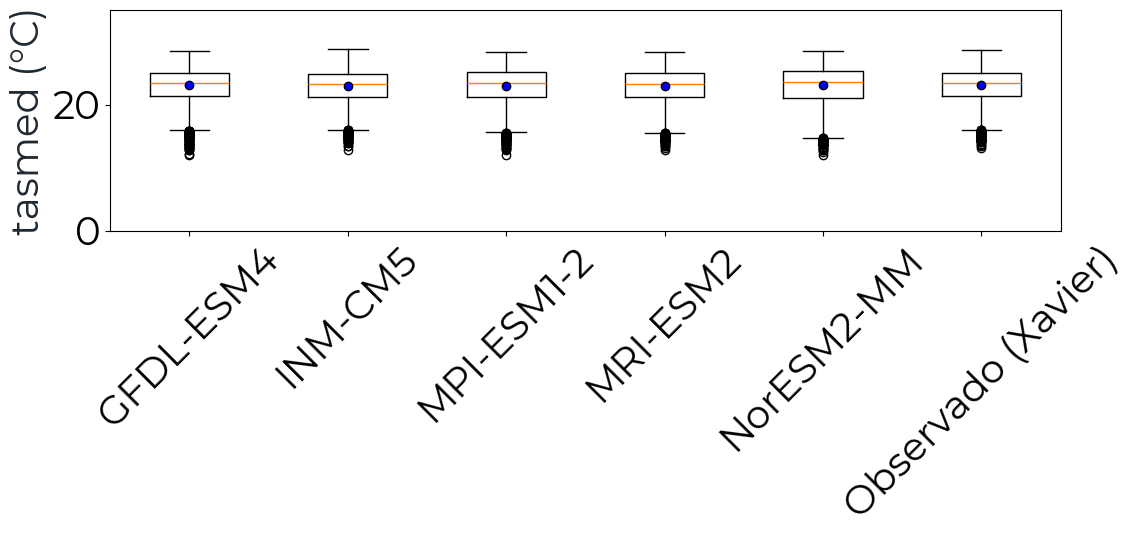

✔ Boxplot: hist | 1994_2013


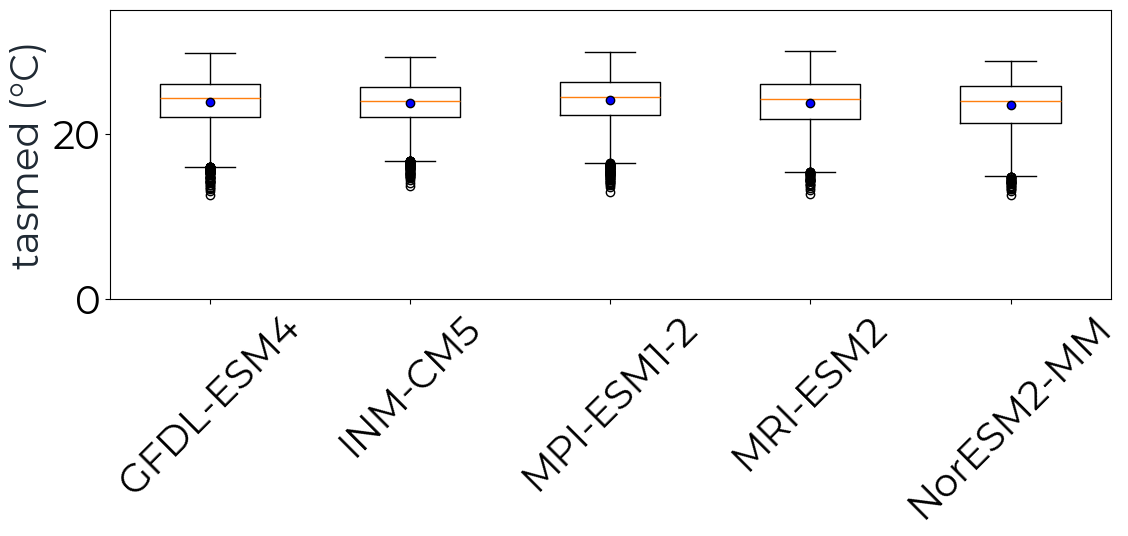

✔ Boxplot: ssp245 | 2021_2040


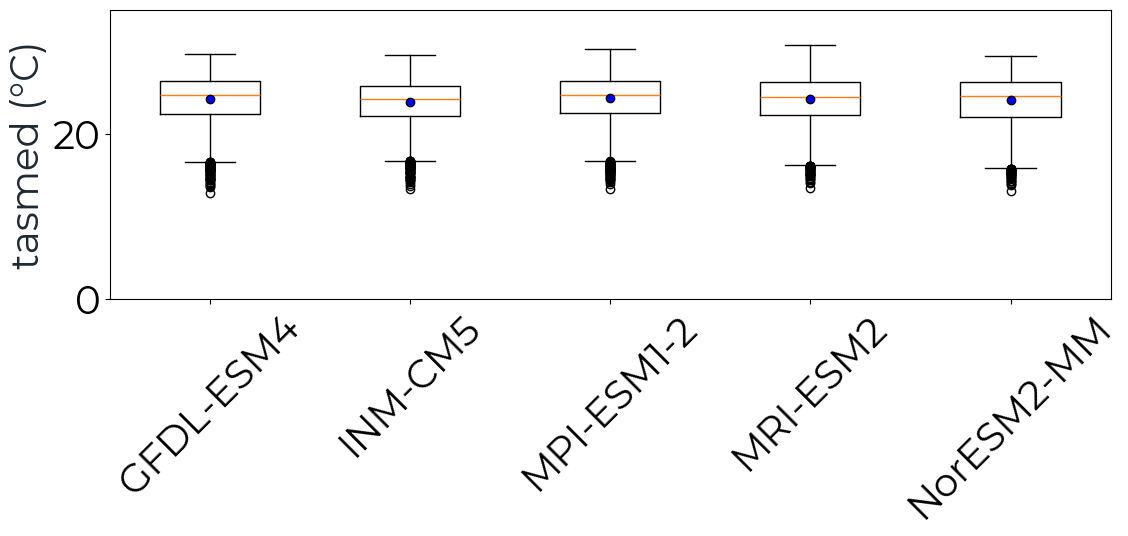

✔ Boxplot: ssp245 | 2041_2060


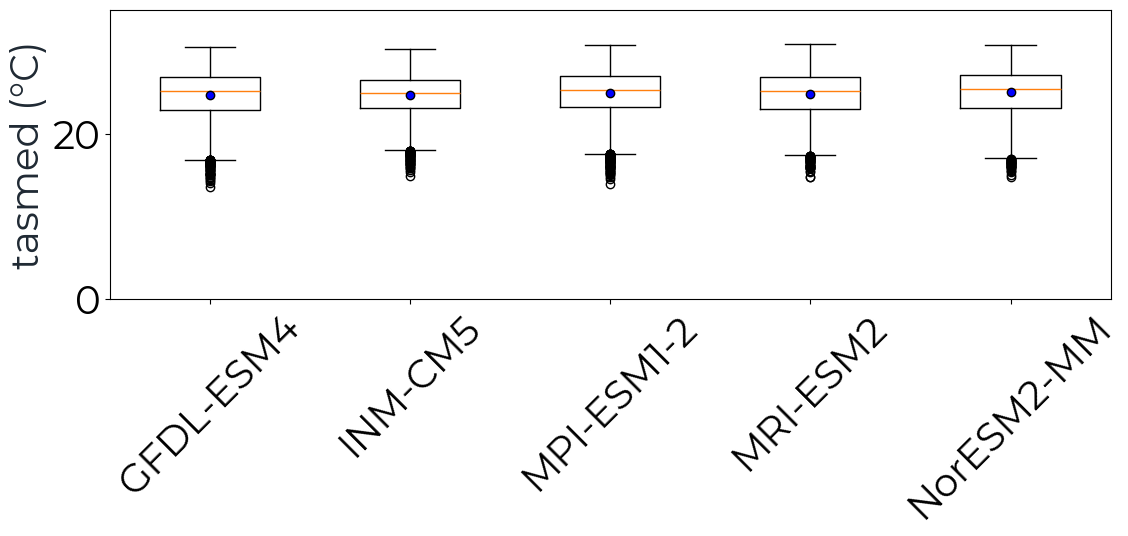

✔ Boxplot: ssp245 | 2081_2100


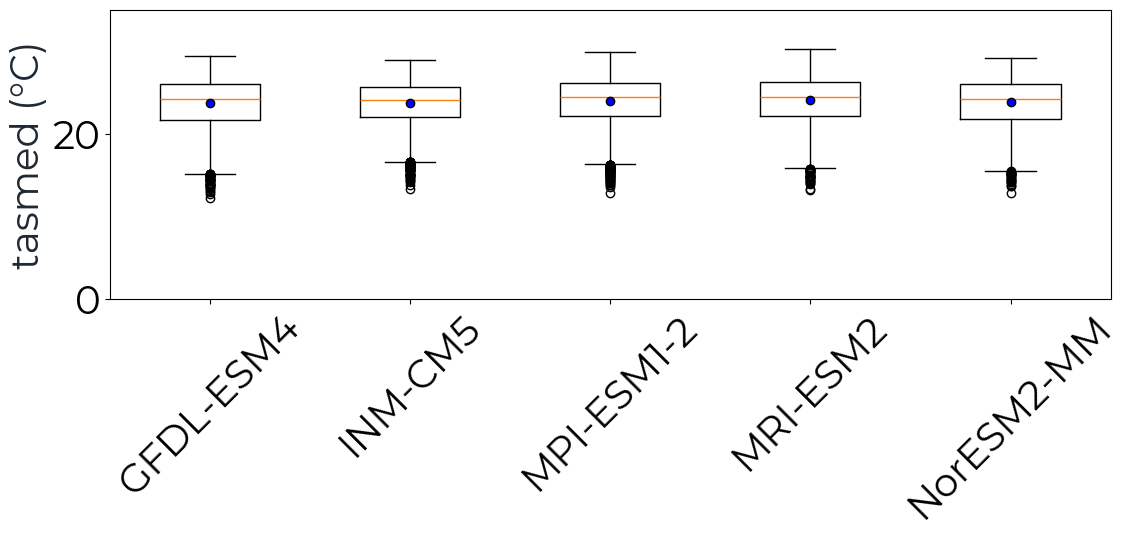

✔ Boxplot: ssp585 | 2021_2040


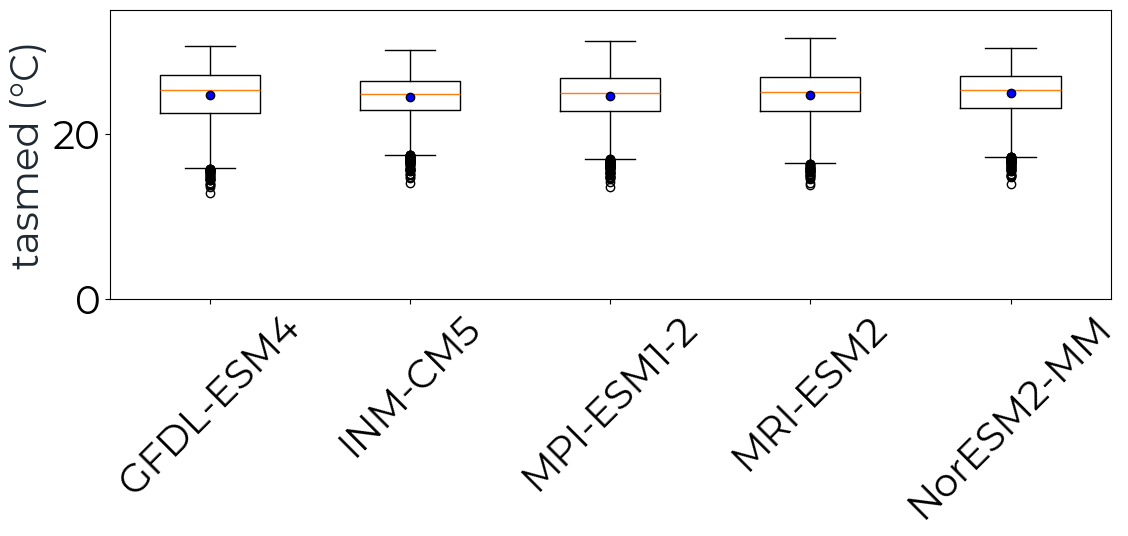

✔ Boxplot: ssp585 | 2041_2060


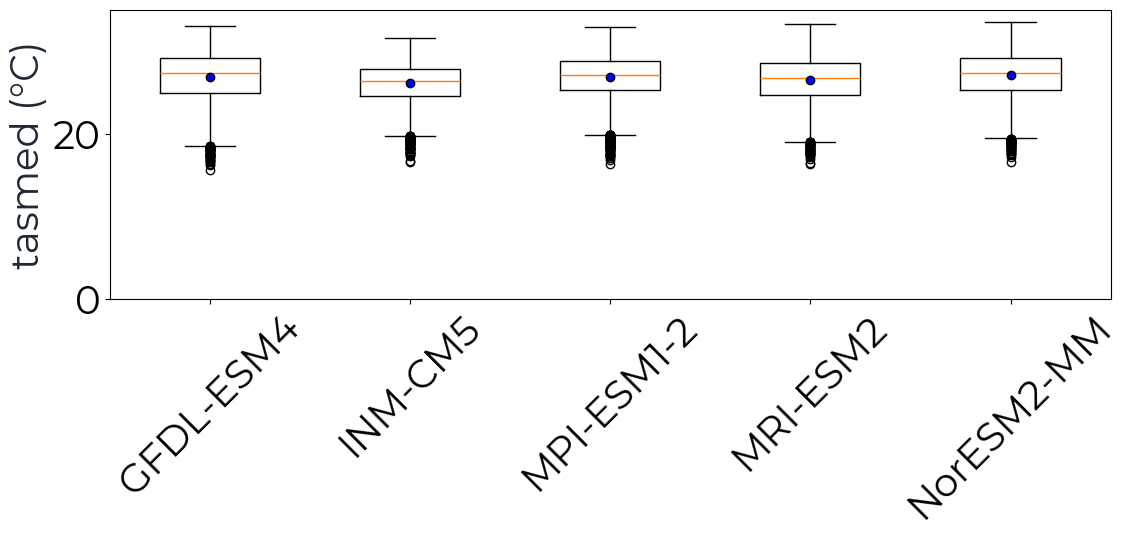

✔ Boxplot: ssp585 | 2081_2100

📁 Boxplots e CSV salvos em: /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/02_BoxPlots


In [18]:
all_stats_consolidated = []

for scenario, periods in scenarios.items():
    scenario_dir = os.path.join(BOX_OUTPUT_BASE, scenario)

    for period_label in periods:
        period_dir = os.path.join(scenario_dir, period_label)
        data_dict = {}

        for model in models:
            nc_path = os.path.join(
                period_dir, f'{model}-{variable_climbra}-{scenario}-{period_label}_mean.nc')
            if not os.path.exists(nc_path):
                continue

            with xr.open_dataset(nc_path) as ds:
                values = ds[variable_climbra].to_dataframe().dropna().to_numpy().flatten()
            if len(values) == 0:
                continue

            data_dict[model] = values

            q1, q3 = np.percentile(values, 25), np.percentile(values, 75)
            iqr = q3 - q1
            lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            n_outliers = int(((values < lower) | (values > upper)).sum())

            all_stats_consolidated.append({
                "Cenario": scenario, "Periodo": period_label, "Modelo": model,
                "Media": np.mean(values), "Mediana": np.median(values), "Desvio_Padrao": np.std(values),
                "Min": np.min(values), "Q1": q1, "Q3": q3, "Max": np.max(values), "IQR": iqr,
                "Limite_Inferior": lower, "Limite_Superior": upper, "N_Outliers": n_outliers})

        # Xavier observado — SOMENTE no histórico
        if scenario == 'hist':
            obs_nc = os.path.join(BOX_OUTPUT_BASE, 'obs', '1994_2013',
                                   f'Xavier-{variable_climbra}-obs-1994_2013_mean.nc')
            if os.path.exists(obs_nc):
                with xr.open_dataset(obs_nc) as ds_obs:
                    values_obs = ds_obs[variable_xavier].to_dataframe().dropna().to_numpy().flatten()

                data_dict['Observado (Xavier)'] = values_obs

                q1, q3 = np.percentile(values_obs, 25), np.percentile(values_obs, 75)
                iqr = q3 - q1
                lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
                n_outliers = int(((values_obs < lower) | (values_obs > upper)).sum())

                all_stats_consolidated.append({
                    "Cenario": scenario, "Periodo": period_label, "Modelo": "Xavier (obs)",
                    "Media": np.mean(values_obs), "Mediana": np.median(values_obs), "Desvio_Padrao": np.std(values_obs),
                    "Min": np.min(values_obs), "Q1": q1, "Q3": q3, "Max": np.max(values_obs), "IQR": iqr,
                    "Limite_Inferior": lower, "Limite_Superior": upper, "N_Outliers": n_outliers})

        if data_dict:
            output_plot = os.path.join(
                BOX_RESULT_DIR, f'Boxplot-{variable_climbra}-{scenario}-{period_label}.png')
            generate_boxplot(data_dict, variable_climbra, scenario, period_label, unit, output_plot)
            print(f"✔ Boxplot: {scenario} | {period_label}")

df_boxplot_stats = pd.DataFrame(all_stats_consolidated).sort_values(["Cenario", "Periodo", "Modelo"])
output_csv = os.path.join(BOX_RESULT_DIR, f'Tabela-BoxPlot-{variable_climbra}-PeriodoCompleto.csv')
df_boxplot_stats.to_csv(output_csv, index=False)
print(f"\n📁 Boxplots e CSV salvos em: {BOX_RESULT_DIR}")


## 4. Etapa 3 — Gráficos sazonais (ciclo mensal)

Um gráfico por cenário × período: ciclo anual (Jan–Dez) de cada modelo + ensemble (média dos 5 modelos) + Xavier observado (apenas no histórico). Reaproveita os mesmos NetCDFs de climatologia mensal gerados na Etapa 1 — não lê os dados brutos de novo.

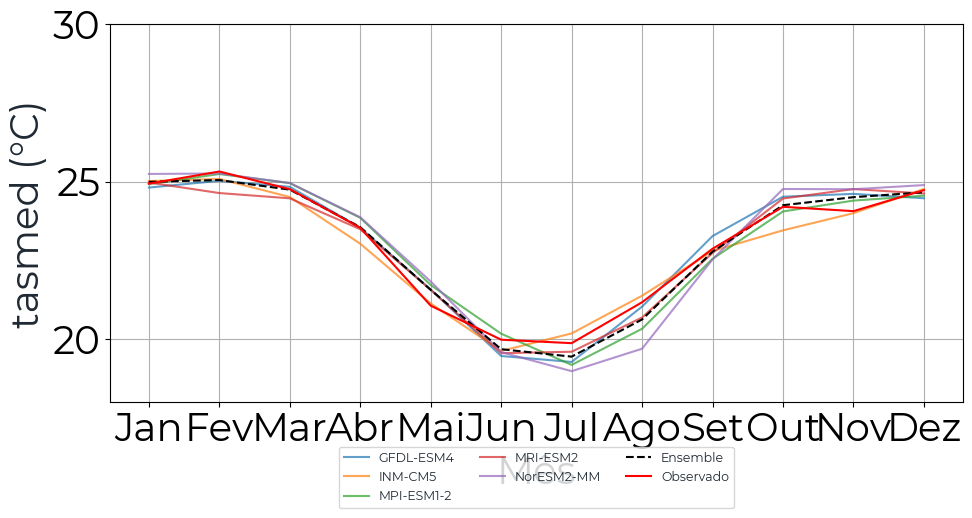

✔ Figura salva: /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/03_Graficos_Sazonais/Graf.Sazonal-tasmed-ensemble-modelos-hist-1994_2013.png


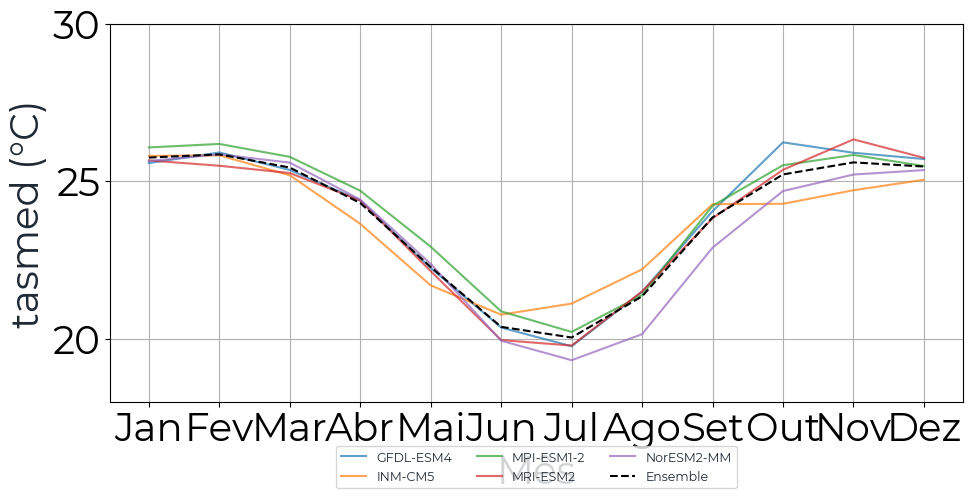

✔ Figura salva: /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/03_Graficos_Sazonais/Graf.Sazonal-tasmed-ensemble-modelos-ssp245-2021_2040.png


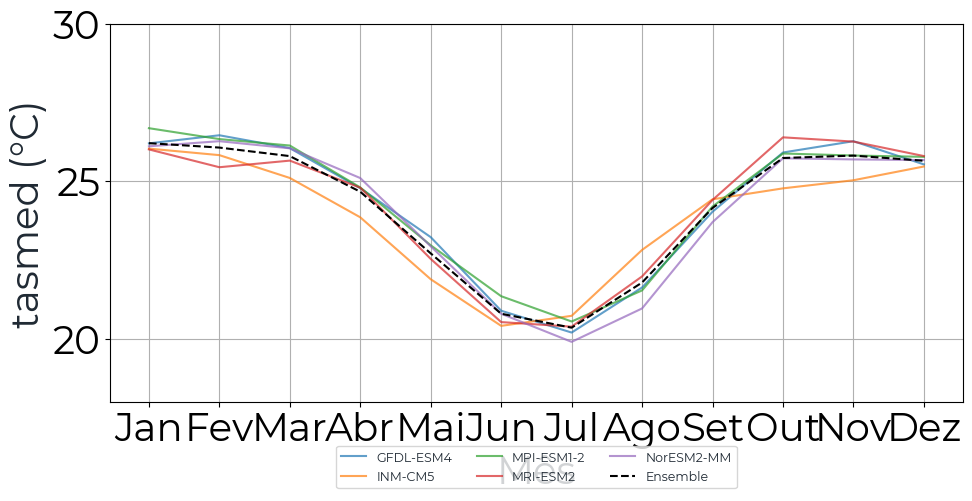

✔ Figura salva: /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/03_Graficos_Sazonais/Graf.Sazonal-tasmed-ensemble-modelos-ssp245-2041_2060.png


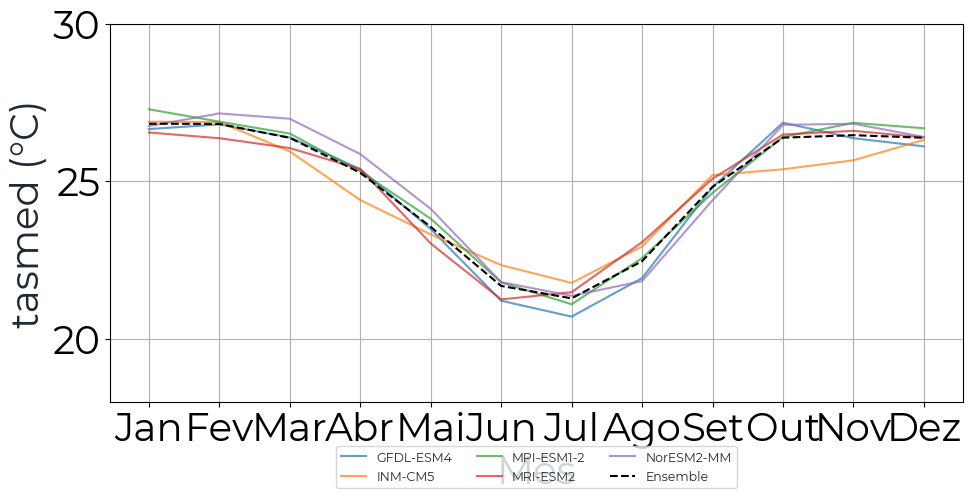

✔ Figura salva: /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/03_Graficos_Sazonais/Graf.Sazonal-tasmed-ensemble-modelos-ssp245-2081_2100.png


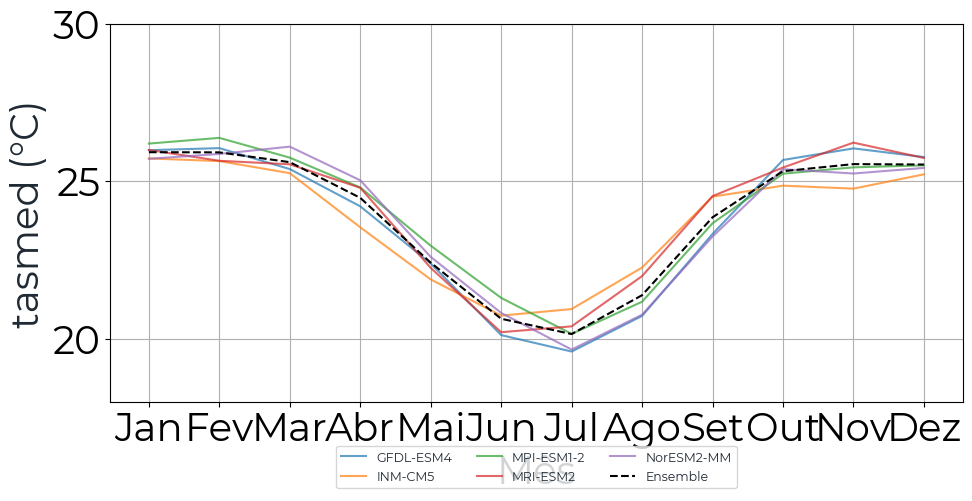

✔ Figura salva: /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/03_Graficos_Sazonais/Graf.Sazonal-tasmed-ensemble-modelos-ssp585-2021_2040.png


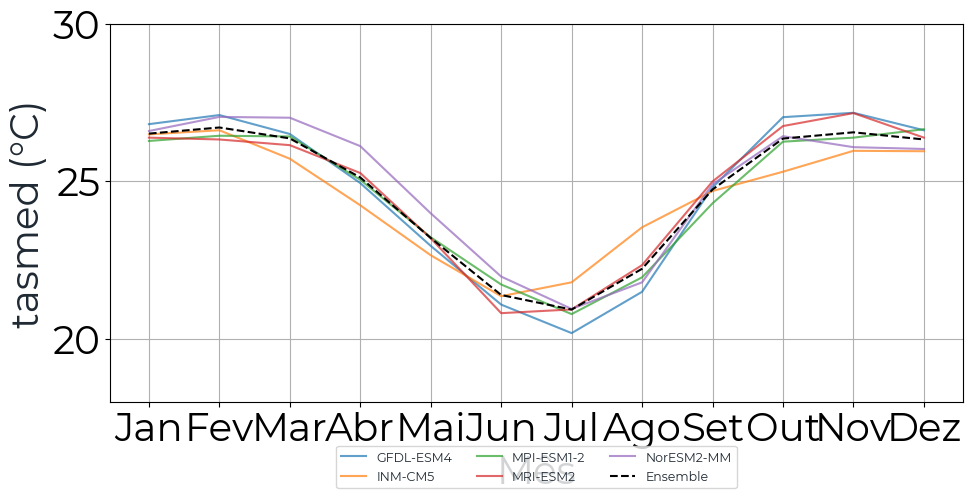

✔ Figura salva: /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/03_Graficos_Sazonais/Graf.Sazonal-tasmed-ensemble-modelos-ssp585-2041_2060.png


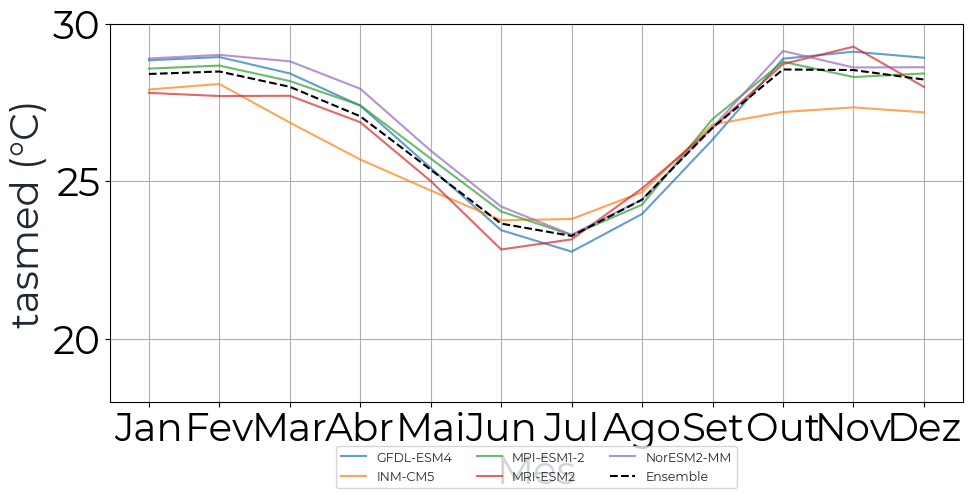

✔ Figura salva: /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/03_Graficos_Sazonais/Graf.Sazonal-tasmed-ensemble-modelos-ssp585-2081_2100.png

📁 Gráficos sazonais salvos em: /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/03_Graficos_Sazonais


In [15]:
for scenario, periods in scenarios.items():

    for period_label in periods:

        plt.figure(figsize=(11, 6))
        ensemble_data = []

        for model in models:
            nc_file = os.path.join(
                BOX_OUTPUT_BASE, scenario, period_label,
                f'{model}-{variable_climbra}-{scenario}-{period_label}_mean.nc')

            if not os.path.exists(nc_file):
                continue

            with xr.open_dataset(nc_file) as ds:
                spatial_dims = [d for d in ds[variable_climbra].dims if d not in ['time', 'month']]
                monthly_means = ds[variable_climbra].mean(dim=spatial_dims).groupby('month').mean().values

            ensemble_data.append(monthly_means)
            plt.plot(months_to_plot, monthly_means, linewidth=1.5, alpha=0.7, label=model)

        if ensemble_data:
            ensemble_mean = np.mean(np.array(ensemble_data), axis=0)
            plt.plot(months_to_plot, ensemble_mean, color='black', linewidth=1.5, linestyle='--', label='Ensemble')

        if scenario == 'hist':
            obs_nc = os.path.join(BOX_OUTPUT_BASE, 'obs', period_label,
                                   f'Xavier-{variable_climbra}-obs-{period_label}_mean.nc')
            if os.path.exists(obs_nc):
                with xr.open_dataset(obs_nc) as ds_obs:
                    spatial_dims_obs = [d for d in ds_obs[variable_xavier].dims if d not in ['time', 'month']]
                    obs_monthly = ds_obs[variable_xavier].mean(dim=spatial_dims_obs).groupby('month').mean().values
                plt.plot(months_to_plot, obs_monthly, color='red', linewidth=1.5, linestyle='-', label='Observado')

        plt.grid(True)
        plt.ylim(18, 30)
        # plt.title(f'Gráfico Sazonal - {variable_climbra} ({unit})\n{scenario_labels[scenario]} – {period_labels[period_label]}')
        plt.xlabel('Mês')
        plt.ylabel(f'{variable_climbra} ({unit})')
        plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=3, fontsize=9, frameon=True)
        plt.subplots_adjust(bottom=0.25)

        output_plot = os.path.join(
            SEAS_OUTPUT_DIR, f'Graf.Sazonal-{variable_climbra}-ensemble-modelos-{scenario}-{period_label}.png')
        plt.savefig(output_plot, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()
        print(f"✔ Figura salva: {output_plot}")

print(f"\n📁 Gráficos sazonais salvos em: {SEAS_OUTPUT_DIR}")


## 5. Etapa 4 — Diagramas de Taylor (período histórico: 1994–2013)

Diferente das etapas anteriores, o Diagrama de Taylor precisa de uma **série temporal mensal única** (não uma climatologia) para calcular correlação de Pearson e desvio padrão — por isso lê de novo os NetCDFs diários brutos do histórico, mas agora calculando a média espacial da região a cada mês (uma série de 240 meses), em vez de uma climatologia de 12 meses por pixel.

In [19]:
XAVIER_NC = f'{xavier_original_dir}/Tmed_monthly_UT_Brazil_v2_19800101_20131231.nc'
VAR_OBS = variable_xavier
VAR_MODELOS = variable_climbra
STD_LABEL = 'Desvio Padrão [°C]'
TITULO = 'Temperatura Média - Sudeste (1994-2013)'

MODELOS = {
    model: f'{climbra_original_dir}/{variable_climbra}/hist/{model}-{variable_climbra}-hist.nc'
    for model in models
}


In [20]:
ds_obs = xr.open_dataset(XAVIER_NC)

# padroniza nomes de coordenadas para lat/lon
rename_map = {}
if "latitude" in ds_obs.coords:
    rename_map["latitude"] = "lat"
if "longitude" in ds_obs.coords:
    rename_map["longitude"] = "lon"
ds_obs = ds_obs.rename(rename_map)

data_obs = ds_obs[VAR_OBS]

mask_obs = regionmask.mask_3D_geopandas(regiao, data_obs.lon, data_obs.lat)
if "region" in mask_obs.dims:
    mask_obs = mask_obs.any("region")

media_espacial_obs = data_obs.where(mask_obs).mean(dim=["lat", "lon"], skipna=True)

df_obs = (
    media_espacial_obs.to_dataframe(name="Observado")
    .reset_index()[["time", "Observado"]]
    .rename(columns={"time": "Date"})
)
# Observação: para tasmed, o arquivo do Xavier usado aqui já é mensal — sem resample adicional.
df_obs = df_obs[(df_obs["Date"] >= DATA_INICIO) & (df_obs["Date"] <= DATA_FIM)].reset_index(drop=True)

print(df_obs.shape)   # deve dar (240, 2)
df_obs.head()


(240, 2)


,Date,Observado
0,1994-01-01,24.247216
1,1994-02-01,26.024165
2,1994-03-01,23.889840
3,1994-04-01,23.035460
4,1994-05-01,21.989587


In [21]:
def mascara_para_arquivo(caminho_nc, var):
    """Recalcula a mascara booleana (lat, lon) da regiao para a grade de um NetCDF especifico."""
    ds = xr.open_dataset(caminho_nc)
    data = ds[var]
    m = regionmask.mask_3D_geopandas(regiao, data.lon, data.lat)
    if "region" in m.dims:
        m = m.any("region")
    ds.close()
    return m.values


def processa_modelo_diario(caminho_nc, var, nome_modelo, chunk=500):
    """Le um NetCDF diario em blocos, recorta pela regiao, agrega para media mensal."""
    mask = mascara_para_arquivo(caminho_nc, var)

    ds = nc.Dataset(caminho_nc)
    variavel = ds.variables[var]
    time_var = ds.variables["time"]
    tempos = nc.num2date(time_var[:], time_var.units, only_use_cftime_datetimes=False)
    tempos = pd.to_datetime([t.isoformat() for t in tempos])

    n_tempo = variavel.shape[0]
    medias = np.empty(n_tempo, dtype=np.float64)

    for inicio in range(0, n_tempo, chunk):
        fim = min(inicio + chunk, n_tempo)
        bloco = np.asarray(variavel[inicio:fim, :, :])
        bloco_mascarado = np.where(mask[np.newaxis, :, :], bloco, np.nan)
        medias[inicio:fim] = np.nanmean(bloco_mascarado, axis=(1, 2))

    ds.close()

    df = pd.DataFrame({"Date": tempos, nome_modelo: medias})
    df = df.set_index("Date").resample("MS").mean().reset_index()
    df = df[(df["Date"] >= DATA_INICIO) & (df["Date"] <= DATA_FIM)].reset_index(drop=True)
    return df


dfs_modelos = {}
for nome, caminho in MODELOS.items():
    print(f"Processando {nome}...")
    dfs_modelos[nome] = processa_modelo_diario(caminho, VAR_MODELOS, nome)
    print(f"  -> {dfs_modelos[nome].shape[0]} meses, media={dfs_modelos[nome][nome].mean():.3f}")


Processando GFDL-ESM4...


/tmp/ipykernel_7671/2272415740.py:29: RuntimeWarning: Mean of empty slice
  medias[inicio:fim] = np.nanmean(bloco_mascarado, axis=(1, 2))


  -> 240 meses, media=23.046
Processando INM-CM5...


/tmp/ipykernel_7671/2272415740.py:29: RuntimeWarning: Mean of empty slice
  medias[inicio:fim] = np.nanmean(bloco_mascarado, axis=(1, 2))


  -> 240 meses, media=22.925
Processando MPI-ESM1-2...


...

  -> 240 meses, media=23.004
Processando MRI-ESM2...


/tmp/ipykernel_7671/2272415740.py:29: RuntimeWarning: Mean of empty slice
  medias[inicio:fim] = np.nanmean(bloco_mascarado, axis=(1, 2))


  -> 240 meses, media=22.974
Processando NorESM2-MM...


/tmp/ipykernel_7671/2272415740.py:29: RuntimeWarning: Mean of empty slice
  medias[inicio:fim] = np.nanmean(bloco_mascarado, axis=(1, 2))


  -> 240 meses, media=23.041


In [22]:
df_final = df_obs.copy()
for nome, df_m in dfs_modelos.items():
    df_final = df_final.merge(df_m, on="Date", how="inner")

print(df_final.shape)
df_final.to_csv("dados_combinados.csv", index=False)
df_final.head()


(240, 7)


,Date,Observado,GFDL-ESM4,INM-CM5,MPI-ESM1-2,MRI-ESM2,NorESM2-MM
0,1994-01-01,24.247216,25.818989,24.249317,24.723251,26.021221,24.277201
1,1994-02-01,26.024165,24.812846,24.938331,25.670887,24.586083,25.057520
2,1994-03-01,23.889840,24.033818,24.642005,26.444204,24.550999,24.283858
3,1994-04-01,23.035460,22.846006,22.785428,24.646566,23.508660,23.689410
4,1994-05-01,21.989587,21.093449,20.939773,23.116498,22.172645,21.256098


In [23]:
def compute_stats(observado, modelo):
    """Retorna (desvio padrao, correlacao de Pearson) entre modelo e observado."""
    observado = np.asarray(observado, dtype=float)
    modelo = np.asarray(modelo, dtype=float)
    stddev = np.std(modelo, ddof=1)
    corr = np.corrcoef(observado, modelo)[0, 1]
    return stddev, corr


obs = df_final["Observado"].values
ref_stddev = np.std(obs, ddof=1)

estatisticas = []
for nome in MODELOS:
    std, corr = compute_stats(obs, df_final[nome].values)
    estatisticas.append({"Modelo": nome, "Desvio Padrão": round(std, 3), "Correlação (R)": round(corr, 3)})

tabela_estatisticas = pd.DataFrame(estatisticas).sort_values("Correlação (R)", ascending=False)
print(f"Desvio padrão observado (referência) = {ref_stddev:.3f}")
tabela_estatisticas


Desvio padrão observado (referência) = 2.027


,Modelo,Desvio Padrão,Correlação (R)
1,INM-CM5,1.957,0.892
3,MRI-ESM2,2.163,0.883
4,NorESM2-MM,2.486,0.862
2,MPI-ESM1-2,2.272,0.854
0,GFDL-ESM4,2.252,0.833


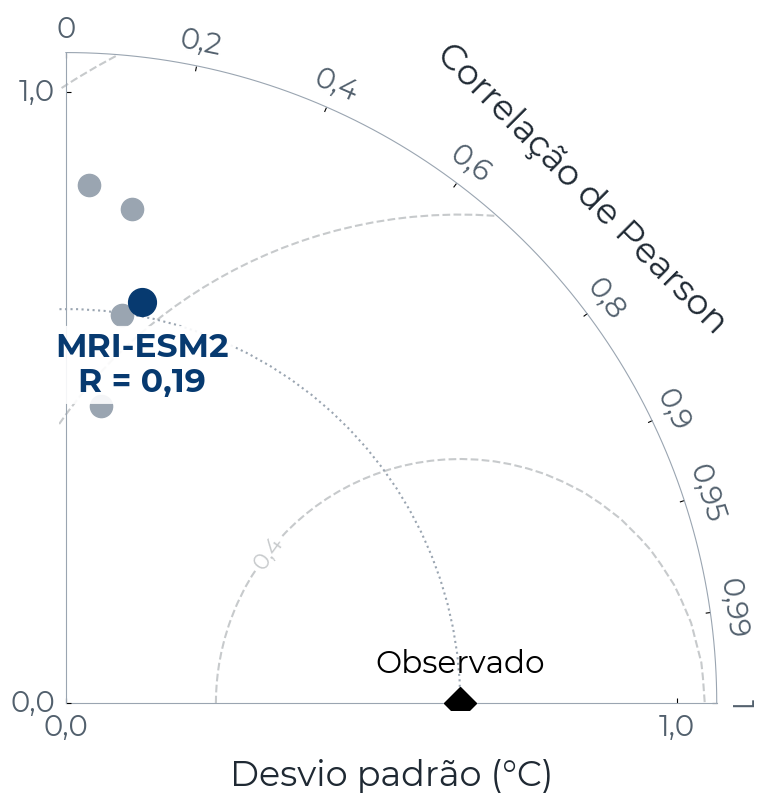

taylor_tasmed_verão.png: melhor = MRI-ESM2 (R = 0,19)  ->  /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/04_Diagramas_Taylor/taylor_tasmed_verão.png


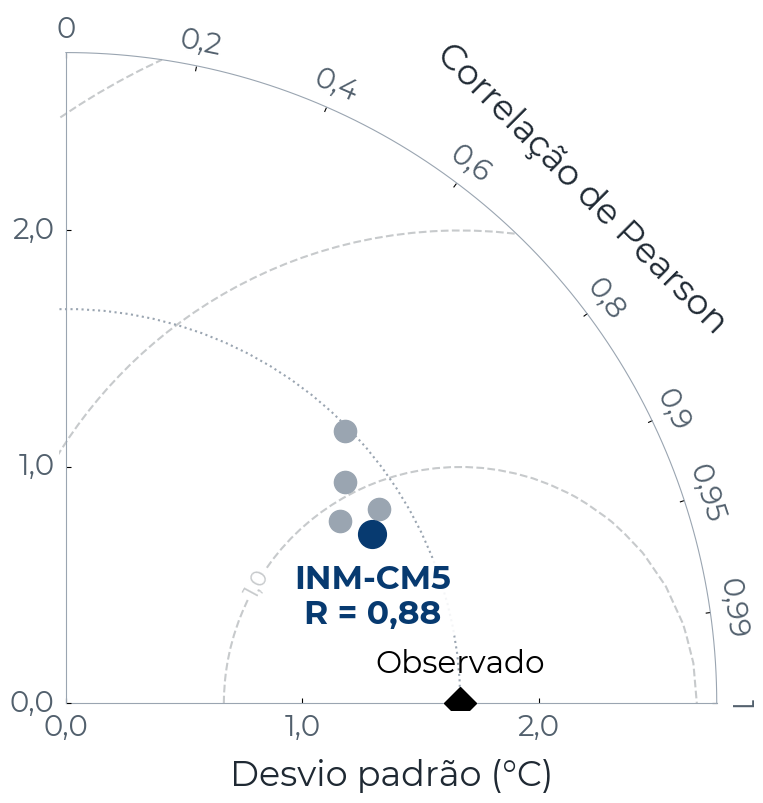

taylor_tasmed_outono.png: melhor = INM-CM5 (R = 0,88)  ->  /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/04_Diagramas_Taylor/taylor_tasmed_outono.png


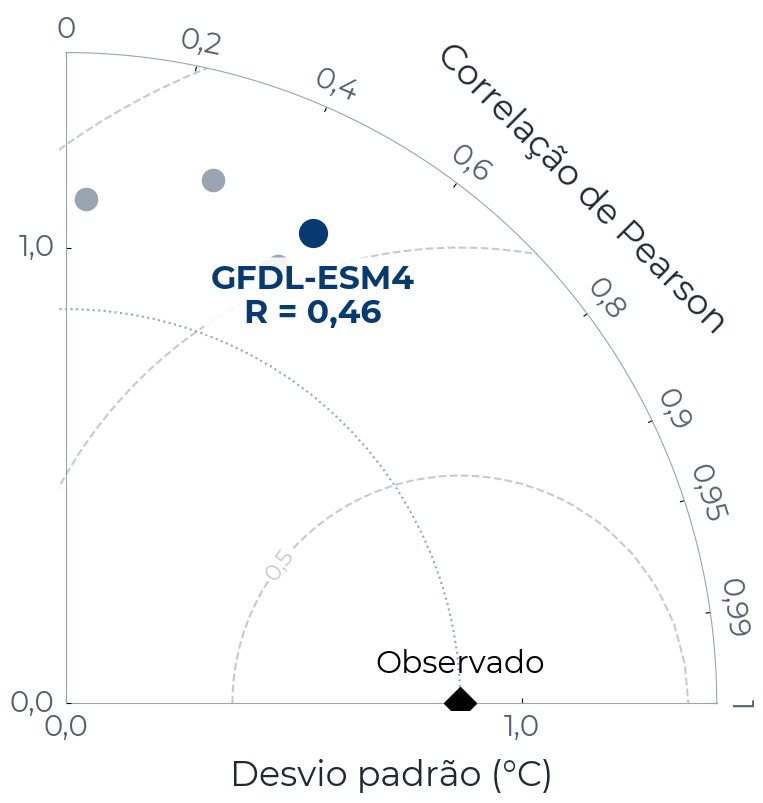

taylor_tasmed_inverno.png: melhor = GFDL-ESM4 (R = 0,46)  ->  /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/04_Diagramas_Taylor/taylor_tasmed_inverno.png


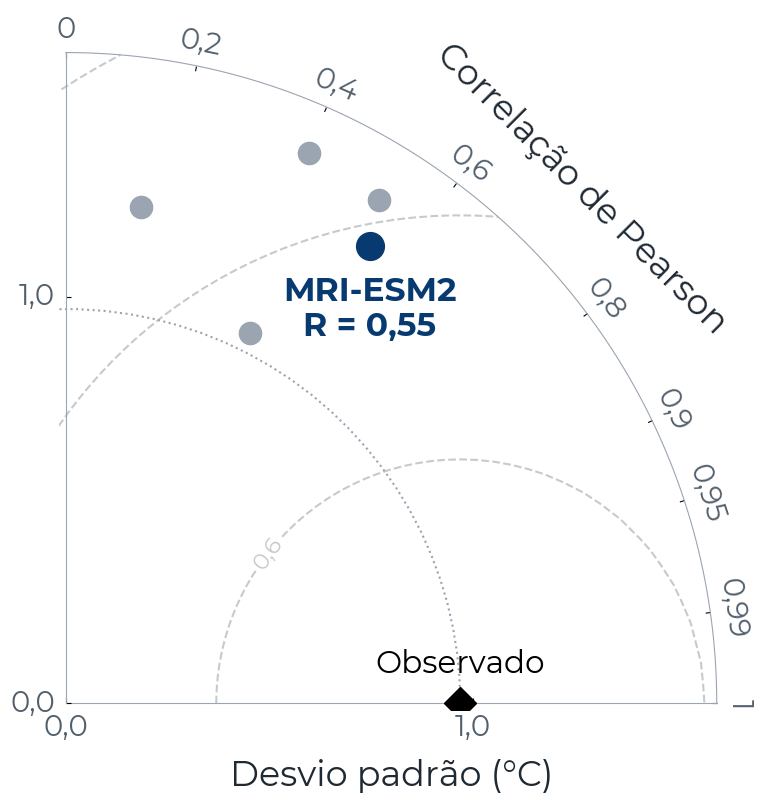

taylor_tasmed_primavera.png: melhor = MRI-ESM2 (R = 0,55)  ->  /content/drive/Shareddrives/Projeto Oidio 2/Resumos e Relatórios/[BIANCA] Resumo Expandido/RBras/tasmed/04_Diagramas_Taylor/taylor_tasmed_primavera.png


,Estacao,Modelo,Desvio Padrão,Correlação (R),Destaque
0,Verão (DJF),GFDL-ESM4,0.849,0.045,False
1,Verão (DJF),INM-CM5,0.490,0.118,False
2,Verão (DJF),MPI-ESM1-2,0.817,0.133,False
3,Verão (DJF),MRI-ESM2,0.669,0.186,True
4,Verão (DJF),NorESM2-MM,0.642,0.142,False
5,Outono (MAM),GFDL-ESM4,1.651,0.715,False
6,Outono (MAM),INM-CM5,1.479,0.875,True
7,Outono (MAM),MPI-ESM1-2,1.557,0.849,False
8,Outono (MAM),MRI-ESM2,1.395,0.832,False
9,Outono (MAM),NorESM2-MM,1.507,0.783,False


In [46]:
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.projections import PolarAxes
import mpl_toolkits.axisartist.floating_axes as FA
import mpl_toolkits.axisartist.grid_finder as GF

# ---- Padrão do pôster (70ª RBras) ----
AZUL, CINZA, CINZA_CLARO = "#073A70", "#9AA5B1", "#C7CACC"
TEXTO, TEXTO_MUTED = "#1F2933", "#52606D"      # mesmas cores do gráfico no PPT
BASE = 28                                      # tamanho base do texto (pt)
FIG_CM = (21.9, 24)                            # espaço de cada figura no pôster

# baixa e registra a Montserrat (o Colab não vem com ela)
FONT_DIR = "/content/fonts"
os.makedirs(FONT_DIR, exist_ok=True)
for peso in ("Regular", "Bold"):
    arq = os.path.join(FONT_DIR, f"Montserrat-{peso}.ttf")
    if not os.path.exists(arq):
        urllib.request.urlretrieve(
            f"https://github.com/JulietaUla/Montserrat/raw/master/fonts/ttf/Montserrat-{peso}.ttf", arq)
    font_manager.fontManager.addfont(arq)

plt.rcParams.update({"font.family": "Montserrat", "font.size": BASE,
                     "text.color": TEXTO, "axes.labelcolor": TEXTO})


def br(x):                    # 0.88 -> "0,88"
    return f"{x:.2f}".replace(".", ",")


class TaylorDiagram:
    """Monta os eixos de um Diagrama de Taylor e permite adicionar pontos."""

    def __init__(self, ref_stddev, fig=None, rect=111, label="Observado",
                 std_range=(0, 1.65), corr_ticks=None, std_label="Desvio Padrão",
                 std_step=1.0):
        self.ref_stddev = ref_stddev
        if corr_ticks is None:
            corr_ticks = np.array([0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.99, 1])
        try:
            tr = PolarAxes.PolarTransform(apply_theta_transforms=False)
        except TypeError:
            tr = PolarAxes.PolarTransform()
        angles = np.arccos(corr_ticks)
        std_ticks = np.arange(0, std_range[1] * ref_stddev + 1e-9, std_step)
        grid_helper = FA.GridHelperCurveLinear(
            tr,
            extremes=(angles.min(), angles.max(),
                      std_range[0] * ref_stddev, std_range[1] * ref_stddev),
            grid_locator1=GF.FixedLocator(angles.tolist()),
            tick_formatter1=GF.DictFormatter(dict(zip(
                angles.tolist(),
                [f"{c:.2f}".rstrip("0").rstrip(".").replace(".", ",") for c in corr_ticks]))),
            grid_locator2=GF.FixedLocator(std_ticks.tolist()),
            tick_formatter2=GF.DictFormatter({v: f"{v:.1f}".replace(".", ",") for v in std_ticks}),
        )
        self.smin, self.smax = std_range[0] * ref_stddev, std_range[1] * ref_stddev
        if fig is None:
            fig = plt.figure(figsize=(FIG_CM[0] / 2.54, FIG_CM[1] / 2.54))
        ax = FA.FloatingSubplot(fig, rect, grid_helper=grid_helper)
        fig.add_subplot(ax)

        ax.axis["top"].set_axis_direction("bottom")
        ax.axis["top"].toggle(ticklabels=True, label=True)
        ax.axis["top"].major_ticklabels.set_axis_direction("top")
        ax.axis["top"].label.set_axis_direction("top")
        ax.axis["top"].label.set_text("Correlação de Pearson")
        ax.axis["left"].set_axis_direction("bottom")
        ax.axis["left"].label.set_text(std_label)
        ax.axis["right"].set_axis_direction("top")
        ax.axis["right"].toggle(ticklabels=True)
        ax.axis["right"].major_ticklabels.set_axis_direction("left")
        ax.axis["bottom"].set_visible(False)
        for lado in ("top", "left", "right"):
            ax.axis[lado].line.set_color(CINZA)
            ax.axis[lado].major_ticklabels.set_fontsize(BASE * 0.75)
            ax.axis[lado].major_ticklabels.set_color(TEXTO_MUTED)
            ax.axis[lado].major_ticklabels.set_pad(8)
            ax.axis[lado].label.set_fontsize(BASE * 0.9)
        ax.axis["top"].label.set_pad(18)
        ax.axis["left"].label.set_pad(14)

        self._ax, self.ax, self.fig = ax, ax.get_aux_axes(tr), fig
        self.ax.plot([0], ref_stddev, marker="D", ms=16, ls="", color="black", zorder=7)
        self.ax.annotate(label, (0, ref_stddev), xytext=(0, 22), textcoords="offset points",
                         ha="center", fontsize=BASE * 0.8, color="black")

    def add_sample(self, stddev, corrcoef, *args, **kwargs):
        l, = self.ax.plot(np.arccos(corrcoef), stddev, *args, **kwargs)
        return l

    def add_rmse_contours(self, levels=4):
        rs, ts = np.meshgrid(np.linspace(self.smin, self.smax), np.linspace(0, np.pi))
        rmse = np.sqrt(self.ref_stddev**2 + rs**2 - 2 * self.ref_stddev * rs * np.cos(ts))
        c = self.ax.contour(ts, rs, rmse, levels, colors=CINZA_CLARO,
                            linestyles="--", linewidths=1.5)
        self.ax.clabel(c, inline=1, fontsize=BASE * 0.6,
                       fmt=lambda v: f"{v:.1f}".replace(".", ","))

    def add_stddev_circle(self):
        t = np.linspace(0, np.pi)
        self.ax.plot(t, np.full_like(t, self.ref_stddev), color=CINZA, ls=":", lw=1.5)


def rmse_centrado(std_ref, std_mod, r):
    """Equação 1: E'² = σf² + σr² − 2·σf·σr·R"""
    return np.sqrt(std_mod**2 + std_ref**2 - 2 * std_mod * std_ref * r)


def plot_taylor_destaque(obs, simulacoes, arquivo, std_label="Desvio Padrão",
                         criterio="rmse", std_step=1.0):
    """simulacoes: dict {nome_modelo: array}. Melhor modelo em azul, demais em cinza.
    criterio: "rmse" (mais perto do observado) ou "r" (maior correlação)."""
    ref_std = np.std(obs, ddof=1)
    stats = {n: compute_stats(obs, v) for n, v in simulacoes.items()}   # (std, corr)

    if criterio == "r":
        melhor = max(stats, key=lambda n: stats[n][1])
    else:
        melhor = min(stats, key=lambda n: rmse_centrado(ref_std, *stats[n]))

    # estende o eixo para R negativo quando algum modelo tiver correlação < 0
    ticks = None
    if min(c for _, c in stats.values()) < 0:
        ticks = np.array([-1, -0.6, -0.2, 0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.99, 1])

    td = TaylorDiagram(ref_std, label="Observado", std_label=std_label,
                       corr_ticks=ticks, std_step=std_step)
    td.add_rmse_contours()
    td.add_stddev_circle()

    for nome, (std, corr) in stats.items():
        if nome != melhor:
            td.add_sample(std, corr, marker="o", ms=16, ls="", color=CINZA, zorder=5)
    std, corr = stats[melhor]
    td.add_sample(std, corr, marker="o", ms=20, ls="", color=AZUL, zorder=6)
    td.ax.annotate(f"{melhor}\nR = {br(corr)}", (np.arccos(corr), std),
                   xytext=(0, -22), textcoords="offset points", ha="center", va="top",
                   fontsize=BASE * 0.85, fontweight="bold", color=AZUL, zorder=10,
                   bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9))

    td.fig.subplots_adjust(left=0.13, right=0.90, bottom=0.10, top=0.88)
    td.fig.savefig(arquivo, dpi=300, facecolor="white")
    plt.show()
    print(f"{os.path.basename(arquivo)}: melhor = {melhor} (R = {br(corr)})  ->  {os.path.abspath(arquivo)}")
    return melhor, stats


# =========================================================
# 10. Um Diagrama de Taylor por estação (padrão do pôster)
# =========================================================
VAR = "tasmed"                                   # "pr" = precipitação | "tasmed" = temperatura
STD_LABEL_POSTER = "Desvio padrão (°C)"  # "Desvio padrão (°C)" para temperatura
STEP = 1.0                                   # espaçamento dos números do eixo; 0.5 se ficarem poucos
CRITERIO = "r"                               # "r" = maior correlação | "rmse" = mais perto do observado

PASTA_SAIDA = TAYLOR_OUTPUT_DIR
os.makedirs(PASTA_SAIDA, exist_ok=True)

MES_PARA_ESTACAO = {
    12: "Verão (DJF)", 1: "Verão (DJF)", 2: "Verão (DJF)",
    3: "Outono (MAM)", 4: "Outono (MAM)", 5: "Outono (MAM)",
    6: "Inverno (JJA)", 7: "Inverno (JJA)", 8: "Inverno (JJA)",
    9: "Primavera (SON)", 10: "Primavera (SON)", 11: "Primavera (SON)",
}
ESTACOES_ORDEM = ["Verão (DJF)", "Outono (MAM)", "Inverno (JJA)", "Primavera (SON)"]
df_final["Estacao"] = pd.to_datetime(df_final["Date"]).dt.month.map(MES_PARA_ESTACAO)

linhas_tabela = []
for estacao in ESTACOES_ORDEM:
    df_est = df_final[df_final["Estacao"] == estacao]
    obs_est = df_est["Observado"].values
    sims_est = {nome: df_est[nome].values for nome in MODELOS}

    sufixo = estacao.split()[0].lower()      # verão, outono, inverno, primavera
    arquivo = os.path.join(PASTA_SAIDA, f"taylor_{VAR}_{sufixo}.png")
    melhor, stats = plot_taylor_destaque(obs_est, sims_est, arquivo,
                                         std_label=STD_LABEL_POSTER,
                                         criterio=CRITERIO, std_step=STEP)

    for nome, (std, corr) in stats.items():
        linhas_tabela.append({"Estacao": estacao, "Modelo": nome,
                              "Desvio Padrão": round(std, 3), "Correlação (R)": round(corr, 3),
                              "Destaque": nome == melhor})

tabela_sazonal = pd.DataFrame(linhas_tabela)
tabela_sazonal.to_csv(os.path.join(PASTA_SAIDA, f"estatisticas_taylor_por_estacao_{VAR}.csv"), index=False)
tabela_sazonal

## Referência

Taylor, K. E. (2001). Summarizing multiple aspects of model performance in a single diagram. *Journal of Geophysical Research*, 106(D7), 7183–7192. https://doi.org/10.1029/2000JD900719